# Evaluation

This notebook evaluates an inference run against a COCO ground truth using the
functions in `utils/eval_utils.py`: COCO mAP/mAR metrics, F1-vs-confidence and FROC curves,
class-aware recall, visual inspection, prompt ensembling and timing comparison. It is
model-agnostic: evaluate any result JSON, whatever detector produced it.

## Prerequisites

> **Running a launcher is optional.** The launchers write their result JSON into the
> `results/` directory, which is gitignored except for one committed file
> (`results/sam3/example_dataset.json`):
>
> ```bash
> python examples/sam3.py
> ```
>
> This produces `results/sam3/example_dataset.json` (edit the config block in the launcher
> to run on your own dataset instead). If you have not run a launcher, cell [3] falls back to
> that committed SAM3 example run, so this notebook works out of the box. Point `OUTPUT_PATH`
> in cell [3] at the result file you want to evaluate.

In [14]:
import glob
import json
import os
from pathlib import Path

from pycocotools.coco import COCO

from utils.eval_utils import (
    detection_evaluation,
    plot_performance,
    plot_f1_confidence_curve,
    plot_fppi_vs_recall,
    class_aware_recall_report,
    visualize_json_results,
    ensemble_coco,
)

# Repo root discovery: works whether the kernel cwd is the repo root or examples/
ROOT = Path.cwd()
while not (ROOT / "utils" / "models.py").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if ROOT == ROOT.parent:  # walked up to the filesystem root
    raise RuntimeError(
        "Repo root not found. Open this notebook from inside the "
        "zero-shot-insect-detection repo directory."
    )

# Ground truth (COCO format) and where the launchers write their results
# (gitignored, except the committed SAM3 example run)
ANNOTATIONS_FILE = str(ROOT / "example_dataset" / "detections_val_20.json")
# RESULTS_DIR = str(ROOT / "results" / "sam3")
RESULTS_DIR = str(ROOT / "results")
IMAGES_DIR = str(ROOT / "example_dataset")

## 1. Load the result JSON

`OUTPUT_PATH` points at one result file in `results/sam3/`: the one produced by
`python examples/sam3.py`, or any of your own runs (each file is a COCO-format JSON whose
`info` block records the run parameters).

In [15]:
# Pick one of your runs:
OUTPUT_PATH = os.path.join(RESULTS_DIR, "my_run.json")

if not os.path.exists(OUTPUT_PATH):
    # Fall back to the committed SAM3 example run, so this notebook works
    # without having run a launcher first (results/sam3 is gitignored, but
    # example_dataset.json is tracked). Set OUTPUT_PATH to your own run
    # to evaluate that instead.
    SHIPPED_EXAMPLE = os.path.join(ROOT, "results", "sam3", "example_dataset.json")
    if os.path.exists(SHIPPED_EXAMPLE):
        print(f"Local run not found; evaluating the committed SAM3 example run:\n  {SHIPPED_EXAMPLE}")
        OUTPUT_PATH = SHIPPED_EXAMPLE
    else:
        raise FileNotFoundError(
            f"{OUTPUT_PATH} not found. Run `python examples/sam3.py` first "
            "(or set OUTPUT_PATH to one of your runs in results/sam3/)."
        )

with open(OUTPUT_PATH) as f:
    run = json.load(f)
print(run["info"]["description"])
print(f"{run['info']['num_detections']} detections on {run['info']['num_images']} images")

My run
5 detections on 9 images


## 2. COCO metrics (mAP / mAR)

`detection_evaluation` wraps the official COCOeval on a single "insect" category at IoU
thresholds from 0.1 to 0.95; `plot_performance` draws the mAP/mAR bars and the
precision-recall curves.

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.00s).
Accumulating evaluation results...
DONE (t=0.01s).
{'mAP@10': np.float64(0.31435643564356436), 'mAR@10': np.float64(0.375), 'mAP@30': np.float64(0.31435643564356436), 'mAR@30': np.float64(0.375), 'mAP@50': np.float64(0.31435643564356436), 'mAR@50': np.float64(0.375), 'mAP@10:95': np.float64(0.24174917491749173), 'mAP@50:95': np.float64(0.18366336633663366), 'mAR@10:95': np.float64(0.2847222222222222), 'mAR@50:95': np.float64(0.2125)}


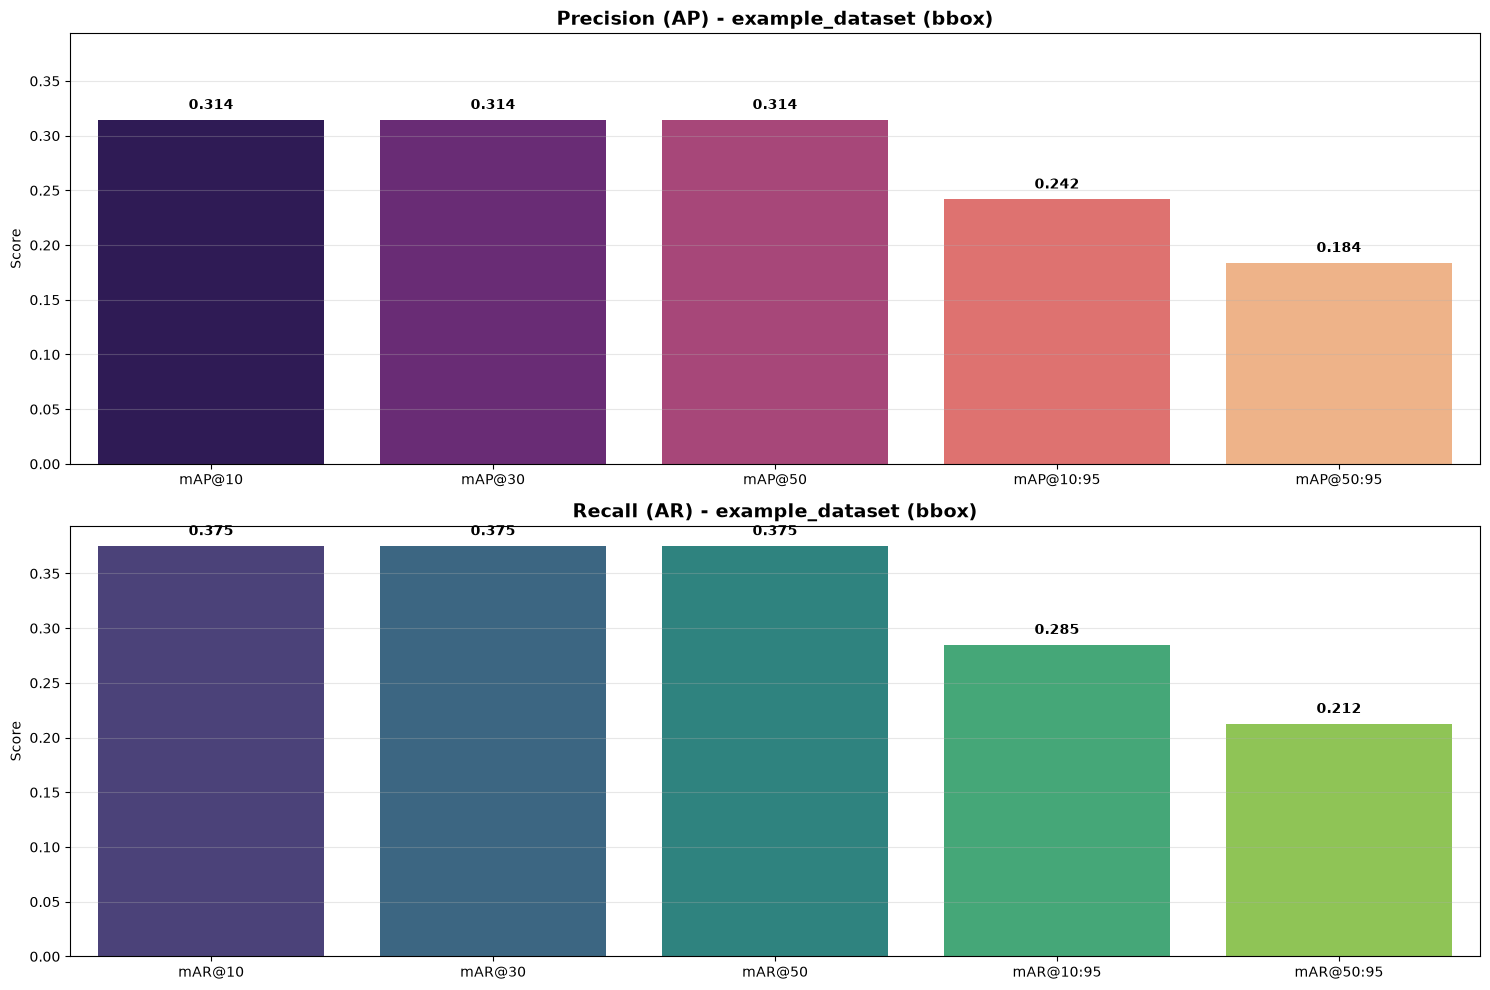

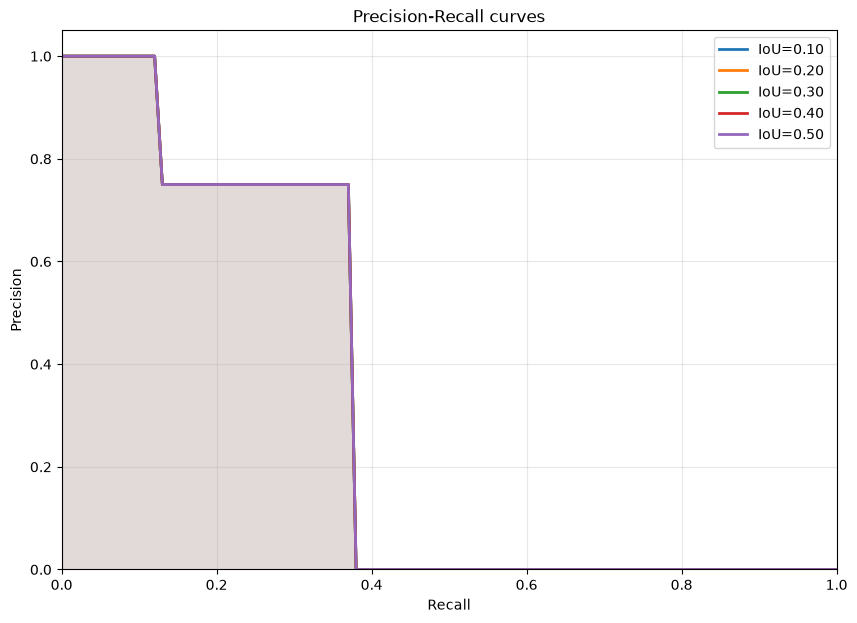

In [16]:
coco_gt = COCO(ANNOTATIONS_FILE)

eval_bbox = detection_evaluation(coco_gt, OUTPUT_PATH, iou_type="bbox")
print(eval_bbox.extra_metrics)

plot_performance(eval_bbox, test_name="example_dataset (bbox)")

## 3. F1 vs confidence and FROC curves

`plot_f1_confidence_curve` greedily matches detections to ground truth at a fixed IoU and
returns the confidence threshold that maximises F1, useful for picking the final
`conf_threshold`. `plot_fppi_vs_recall` draws the FROC curve (recall vs false positives
per image), optionally highlighting that optimal operating point.

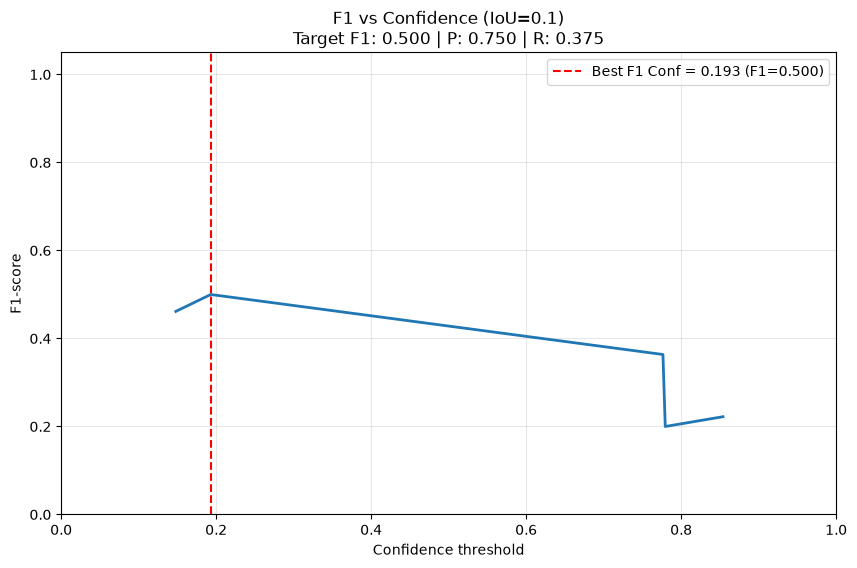

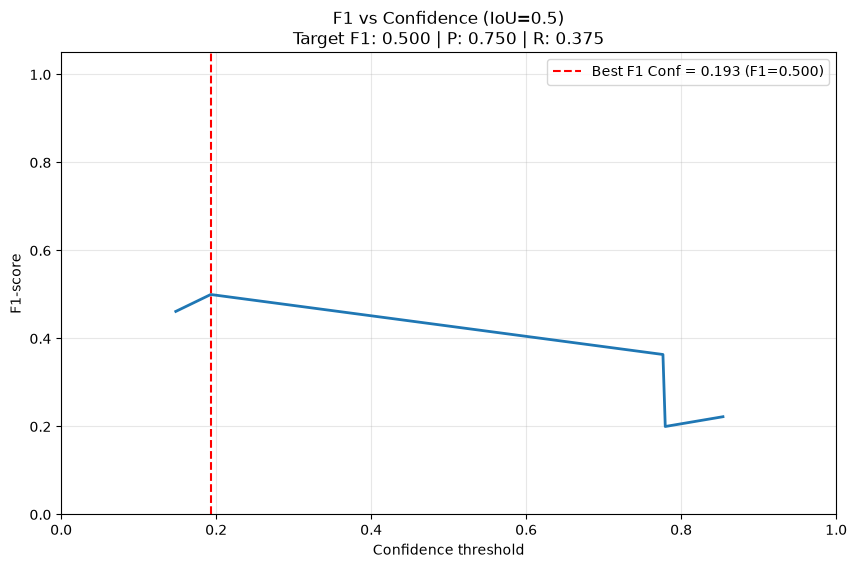

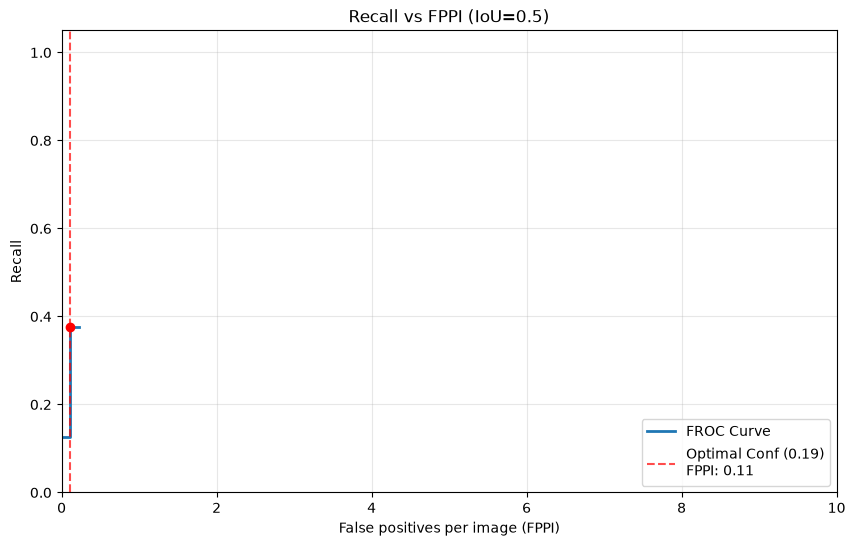

In [17]:
tested_img_ids = coco_gt.getImgIds()

best_conf_01, best_f1_01 = plot_f1_confidence_curve(coco_gt, OUTPUT_PATH, tested_img_ids, iou_threshold=0.1)
best_conf_05, best_f1_05 = plot_f1_confidence_curve(coco_gt, OUTPUT_PATH, tested_img_ids, iou_threshold=0.5)

plot_fppi_vs_recall(coco_gt, OUTPUT_PATH, tested_img_ids, iou_threshold=0.5, max_fppi=10, best_conf=best_conf_05)

## 4. Class-aware recall

`class_aware_recall_report` prints a per-class table (GTs, TPs, recall). Detections are
category-agnostic, so each class is scored against the same predictions; classes without
ground truth are skipped.

In [18]:
class_aware_recall_report(coco_gt, OUTPUT_PATH, tested_img_ids, iou_threshold=0.1, conf_threshold=None)


Class-Aware recall report (Conf Threshold: None)
      Class  GTs  TPs  Recall
 bumblebee+    1    1     1.0
        bee    1    0     0.0
        ant    1    0     0.0
hymenoptera    1    1     1.0
   syrphid-    1    0     0.0
    diptera    1    0     0.0
lepidoptera    1    1     1.0
 coleoptera    1    0     0.0


## 5. Visual inspection

`visualize_json_results` overlays ground truth (blue) and predictions (red) on a random
image (or the one you pick via `image_id`) and crops each detection below it, annotated
with its score and best IoU against the GT boxes. `conf_threshold` filters low-confidence
boxes; `plot_masks=True` also renders the segmentation masks when the result JSON contains
them (SAM3 outputs masks).

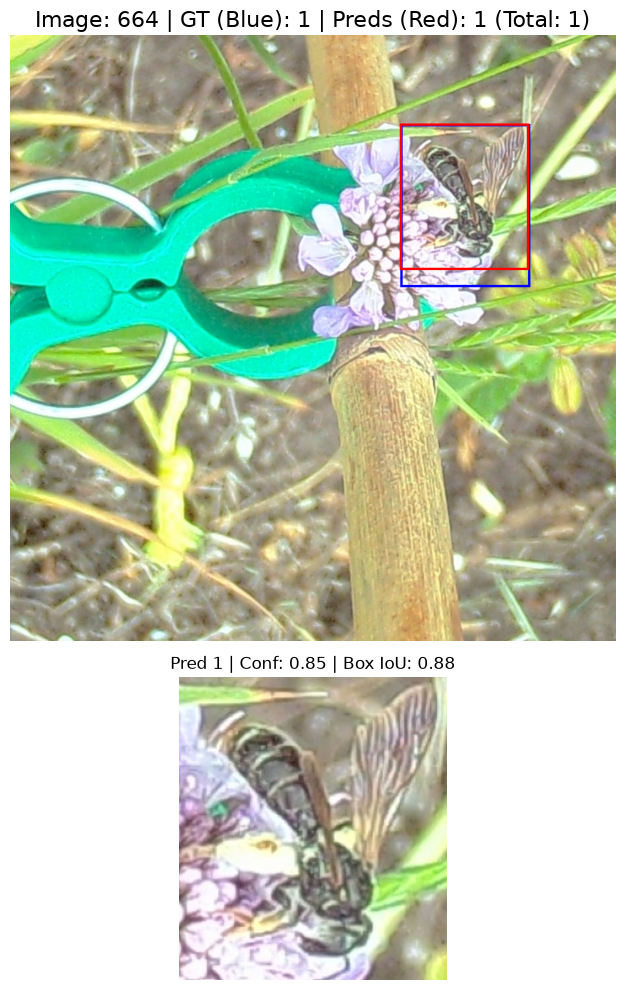

In [23]:
visualize_json_results(
    coco_gt, OUTPUT_PATH, conf_threshold=best_conf_05,
    image_id=None, images_dir=IMAGES_DIR, plot_masks=True,
)

# image_id=8  # pick a specific image by its COCO id (see example_dataset/detections_val_20.json)

## 6. (Optional) Prompt ensemble

Detections depend on the prompt (see `PROMPTS` in `utils/inference.py`). To fuse several
prompt variants: re-run the launcher with a different `TARGETS` (`P1` / `P2` / `P3`),
saving each to its own file, then `ensemble_coco` clusters the boxes across runs and
writes a fused result JSON. Re-point `OUTPUT_PATH` at it and re-run cells 1–5 to evaluate.

In [20]:
json_files = [
    os.path.join(RESULTS_DIR, "example_dataset.json"),  # PROMPTS["P1"]: zero-context
    os.path.join(RESULTS_DIR, "example_dataset_p2.json"),  # PROMPTS["P2"]: contextual phrases
    os.path.join(RESULTS_DIR, "example_dataset_p3.json"),  # PROMPTS["P3"]: taxonomic names
]
ENSEMBLE_OUTPUT_PATH = os.path.join(RESULTS_DIR, "example_dataset_ensemble.json")

if all(os.path.exists(p) for p in json_files):
    ensemble_coco(json_files, ENSEMBLE_OUTPUT_PATH, iou_thr=0.1, num_models=len(json_files))
    print("Ensemble written to:", ENSEMBLE_OUTPUT_PATH)
else:
    print("Skipped: generate the single-prompt results first (re-run the launcher with")
    print('TARGETS = PROMPTS["P2"] / ["P3"] and the file names above).')

Skipped: generate the single-prompt results first (re-run the launcher with
TARGETS = PROMPTS["P2"] / ["P3"] and the file names above).


## 7. Inference time

The `info` block of every result JSON records the wall-clock inference time; this cell
reports seconds per image across all your runs in `results/sam3/`.

In [21]:
def compute_inference_time_per_image(json_path):
    with open(json_path) as f:
        info = json.load(f).get("info", {})
        t, n = info.get("inference_time_sec"), info.get("num_images")
        return t / n if t is not None and n else None

for json_file in sorted(glob.glob(os.path.join(RESULTS_DIR, "*.json"))):
    sec_per_img = compute_inference_time_per_image(json_file)
    label = f"{sec_per_img:.4f} sec/image" if sec_per_img is not None else "no timing info"
    print(f"{os.path.basename(json_file)}: {label}")

my_run.json: 0.2900 sec/image
